# Layer-substitutability pipeline — Colab driver
**Crash-safe design:** results write DIRECTLY to Google Drive (no copy step to forget), finished stages auto-skip, and sweeps resume mid-stage from their partial CSV. If a session dies: rerun the same cell — it continues where it stopped. Only `fit` is atomic (one ~40–80 min pass); everything else resumes row-by-row.

Run **one cell at a time**. Runtime → Change runtime type → GPU first.

In [1]:
#RUN 1
from google.colab import drive
drive.mount('/content/drive')
OUT = "/content/drive/MyDrive/blackboxnlp/results"
!mkdir -p $OUT

Mounted at /content/drive


In [3]:
#UPLOAD P3-zip, run2, taskseval, THEN RUN
!pip -q install transformers==4.46.3 datasets==3.1.0 accelerate pandas matplotlib
!unzip -oq pipeline-5.zip -d /content/
%cd /content/pipeline-5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 43.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 113.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.19.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.9.0 which is incompatible.
/content/pipeline-5


In [4]:
# Llama only — accept license on its HF page, add HF_TOKEN in Colab Secrets
from google.colab import userdata
from huggingface_hub import login
try: login(token=userdata.get('HF_TOKEN'))
except Exception as e: print('no token (fine for Qwen/BERT/etc):', e)

## Qwen2-1.5B (run cells top to bottom; each auto-skips if already done)

In [ ]:
!python run.py --model qwen2-1.5b --stage fit --out $OUT

2026-07-07 18:32:51.000070: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 354.07it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[skip] /content/drive/MyDrive/blackboxnlp/results/qwen2-1.5b/W.pt exists (use --force to redo)
Traceback (most recent call last):
  File "/content/pipeline-3/run.py", line 209, in <module>
    main()
  File "/content/pipeline-3/run.py", line 122, in main
    Ws, caches = load_fit(cfg, device)
                 ^^^^^^^^^^^^^^^^^^^^^
  File "/content/pipeline-3/run.py", line 

In [ ]:
import pandas as pd
pd.read_csv(f"{OUT}/qwen2-1.5b/r2.csv")  # r2_delta = the framing column

,layer,lam,r2_full,r2_identity,r2_delta,r2_full_std,r2_delta_std,stack
0,0,0.10,0.721351,-0.324468,0.721082,0.000024,0.000024,main
1,1,0.01,0.811207,0.020504,0.806427,0.000538,0.000551,main
2,2,0.01,0.987928,0.982174,0.289622,0.000003,0.000197,main
3,3,1000.00,0.986798,0.971359,0.526353,0.000003,0.000105,main
4,4,0.01,0.986855,0.979088,0.348447,0.000002,0.000083,main
5,5,0.01,0.985852,0.976172,0.376487,0.000014,0.000639,main
6,6,1000.00,0.984587,0.972973,0.410848,0.000018,0.000694,main
7,7,1000.00,0.984539,0.971044,0.425361,0.000007,0.000241,main
8,8,1000.00,0.985434,0.971173,0.451071,0.000003,0.000099,main
9,9,0.01,0.988908,0.978733,0.459058,0.000003,0.000138,main


In [ ]:
!python run.py --model qwen2-1.5b --stage ppl --out $OUT

2026-07-07 16:57:00.740973: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 388.31it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[openwebtext] intact: 13.206
  L 0 skip=104305.665  linear=30.901
  L 1 skip=90.174  linear=117.295
  L 2 skip=17.726  linear=15.285
  L 3 skip=15.322  linear=14.824
  L 4 skip=14.397  linear=14.301
  L 5 skip=14.392  linear=14.097
  L 6 skip=14.58  linear=14.178
  L 7 skip=14.361  linear=13.9
  L 8 skip=14.874  linear=14.207
  L 9 skip=14.169  linear=13.838
  L10 skip=14.

In [ ]:
# replace just the one file (upload run.py via the file pane):
!cp /content/run.py /content/pipeline-3/run.py
!python run.py --model qwen2-1.5b --stage multi --out $OUT

2026-07-07 18:37:34.757063: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 222.66it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[load_fit] valcache.pt missing; will rebuild if a stage needs it
  k=1 start= 0 skip=124450.35  linear=85.697
  k=1 start= 4 skip=17.261  linear=17.475
  k=1 start= 8 skip=17.928  linear=16.51
  k=1 start=12 skip=16.046  linear=15.734
  k=1 start=16 skip=16.348  linear=16.005
  k=1 start=20 skip=17.694  linear=16.593
  k=1 start=24 skip=18.173  linear=17.165
  k=2 start= 0

In [ ]:
!python run.py --model qwen2-1.5b --stage multi --out $OUT

2026-07-07 18:56:17.801731: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 482.16it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[load_fit] valcache.pt missing; will rebuild if a stage needs it
  [resume] /content/drive/MyDrive/blackboxnlp/results/qwen2-1.5b/multi.csv: 28 rows already done


In [ ]:
!python run.py --model qwen2-1.5b --stage rank --out $OUT

2026-07-07 18:57:30.196676: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 381.55it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[load_fit] valcache.pt missing; will rebuild if a stage needs it
[valcache] rebuilding from val split (~2-3 min)...
  L7 r=   8 -> {'layer': 7, 'rank': 8, 'r2': 0.16432106494903564, 'metric': 185127.944}
  L7 r=  32 -> {'layer': 7, 'rank': 32, 'r2': 0.2079654335975647, 'metric': 92981.976}
  L7 r= 128 -> {'layer': 7, 'rank': 128, 'r2': 0.32302695512771606, 'metric': 10600.

In [ ]:
!python run.py --model qwen2-1.5b --stage mlp --out $OUT

2026-07-07 19:10:08.386476: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 416.41it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[skip] /content/drive/MyDrive/blackboxnlp/results/qwen2-1.5b/mlp.csv exists (use --force to redo)


In [ ]:
!python run.py --model qwen2-1.5b --stage randinit --out $OUT

2026-07-07 19:12:24.183825: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 306.79it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[fit_randinit] batch 0, tokens/stack ~ 4,096
[fit_randinit] batch 50, tokens/stack ~ 185,930
[fit_randinit] batch 100, tokens/stack ~ 364,490
[fit_randinit] batch 150, tokens/stack ~ 547,626
[ridge_randinit] main L 0 full=0.095±0.000 ident=-0.126 DELTA=0.094±0.000
[ridge_randinit] main L 1 full=0.566±0.000 ident=0.396 DELTA=0.235±0.000
[ridge_randinit] main L 2 full=0.714±

In [ ]:
#RUN THIS
!cp /content/tasks_eval.py /content/pipeline-3/subst/tasks_eval.py
!cp /content/run-2.py /content/pipeline-3/run.py
#!python run.py --model qwen2-1.5b --stage tasks --out $OUT

In [ ]:
!pip -q install lm_eval==0.4.5 && python run.py --model qwen2-1.5b --stage tasks --out $OUT

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.2/314.2 kB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 9.6 MB/s eta 0:00:00
2026-07-07 19:33:49.521022: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 135.37it/s]
[data] fit/eval web cor

## LLaMA-3.2-1B (new session or after Qwen — same pattern)

In [ ]:
!rm /content/drive/MyDrive/blackboxnlp/results/llama3.2-1b/valcache.pt
!rm /content/drive/MyDrive/blackboxnlp/results/qwen2-1.5b/valcache.pt  # if it exists there

In [ ]:
!python run.py --model llama3.2-1b --stage fit --out $OUT --force

2026-07-08 18:22:21.913040: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 104.70it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
llama3.2-1b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[fit] batch 0, tokens/stack ~ 4,096
[fit] batch 50, tokens/stack ~ 185,288
[fit] batch 100, tokens/stack ~ 362,914
[fit] batch 150, tokens/stack ~ 545,322
[fit] batch 200, tokens/stack ~ 728,863
[fit] batch 250, tokens/stack ~ 906,802
[fit] batch 300, tokens/stack ~ 1,085,144
[fit] batch 350, tokens/stack ~ 1,265,768
[fit] batch 400, tokens/stack ~ 1,439,668
[fit] batch 4

In [ ]:
!python run.py --model llama3.2-1b --stage fit --out $OUT

2026-07-08 18:07:26.291675: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 207.26it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
llama3.2-1b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[fit] batch 0, tokens/stack ~ 4,096
[fit] batch 50, tokens/stack ~ 185,288
[fit] batch 100, tokens/stack ~ 362,914
Traceback (most recent call last):
  File "/content/pipeline-3/run.py", line 237, in <module>
    main()
  File "/content/pipeline-3/run.py", line 140, in main
    Ws, caches = stage_fit(cfg, spec, tok, model, device, fit, val)
                 ^^^^^^^^^^^^^^

In [ ]:
!python run.py --model llama3.2-1b --stage ppl --out $OUT

2026-07-08 17:10:13.425551: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 115.43it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
llama3.2-1b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[openwebtext] intact: 13.247
  L 0 skip=24023.254  linear=25.539
  L 1 skip=1604.14  linear=17.677
  L 2 skip=22.009  linear=17.271
  L 3 skip=27.497  linear=17.045
  L 4 skip=21.418  linear=15.808
  L 5 skip=19.977  linear=14.927
  L 6 skip=17.127  linear=14.415
  L 7 skip=17.756  linear=14.396
  L 8 skip=19.016  linear=15.305
  L 9 skip=21.698  linear=16.546
  L10 skip=

In [ ]:
!python run.py --model llama3.2-1b --stage multi --out $OUT

2026-07-08 17:48:21.064877: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 241.75it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
llama3.2-1b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
  k=1 start= 0 skip=27258.099  linear=36.375
  k=1 start= 2 skip=32.338  linear=27.65
  k=1 start= 4 skip=31.675  linear=23.403
  k=1 start= 6 skip=24.157  linear=20.462
  k=1 start= 8 skip=27.328  linear=22.09
  k=1 start=10 skip=32.365  linear=24.733
  k=1 start=12 skip=28.349  linear=25.379
  k=1 start=14 skip=39.875  linear=25.825
  k=2 start= 0 skip=24353.29  linear=

In [ ]:
!python run.py --model llama3.2-1b --stage rank --out $OUT

2026-07-08 19:05:46.799570: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 197.35it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
llama3.2-1b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
  L4 r=   8 -> {'layer': 4, 'rank': 8, 'r2': -0.007382869720458984, 'metric': 83200.374}
  L4 r=  32 -> {'layer': 4, 'rank': 32, 'r2': 0.07918399572372437, 'metric': 112078.452}
  L4 r= 128 -> {'layer': 4, 'rank': 128, 'r2': 0.38007593154907227, 'metric': 226865.291}
  L4 r= 512 -> {'layer': 4, 'rank': 512, 'r2': 0.7345585823059082, 'metric': 155.948}
  L4 r=2048 -> {'lay

In [ ]:
!python run.py --model llama3.2-1b --stage mlp --out $OUT

2026-07-08 19:12:34.174653: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 187.69it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
llama3.2-1b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
  MLP L4: R2=0.983
  MLP L8: R2=0.974
  MLP L12: R2=0.912


In [ ]:
!python run.py --model llama3.2-1b --stage randinit --out $OUT

2026-07-08 19:17:31.620600: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 216.67it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
llama3.2-1b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[fit_randinit] batch 0, tokens/stack ~ 4,096
[fit_randinit] batch 50, tokens/stack ~ 185,288
[fit_randinit] batch 100, tokens/stack ~ 362,914
[fit_randinit] batch 150, tokens/stack ~ 545,322
[ridge_randinit] main L 0 full=0.087±0.000 ident=-0.086 DELTA=0.087±0.000
[ridge_randinit] main L 1 full=0.565±0.000 ident=0.419 DELTA=0.211±0.000
[ridge_randinit] main L 2 full=0.715

In [ ]:
!pip -q install lm_eval==0.4.5 && python run.py --model llama3.2-1b --stage tasks --out $OUT

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.2/314.2 kB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 8.1 MB/s eta 0:00:00
2026-07-08 19:45:01.630400: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 200.62it/s]
[data] fit/eval web cor

saved fig1_delta_ushape


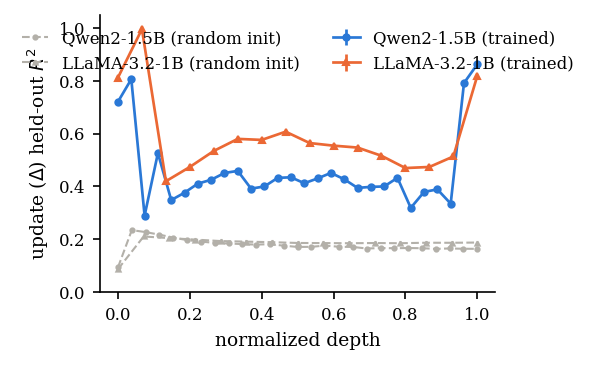

saved fig2_r2_three_curves


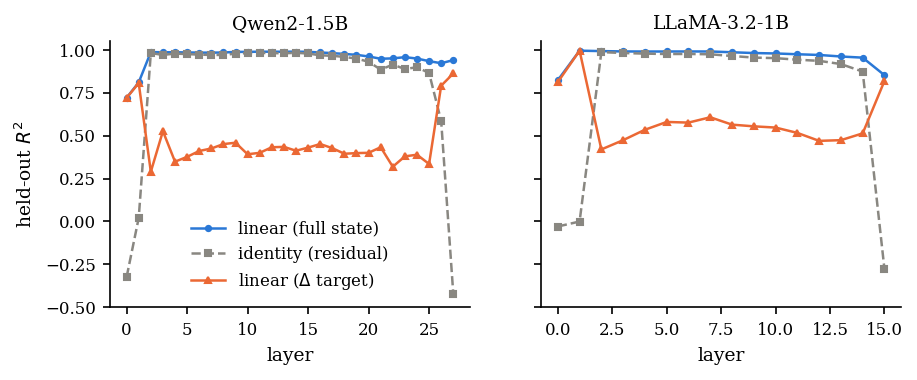

saved fig3_substitutability_profile


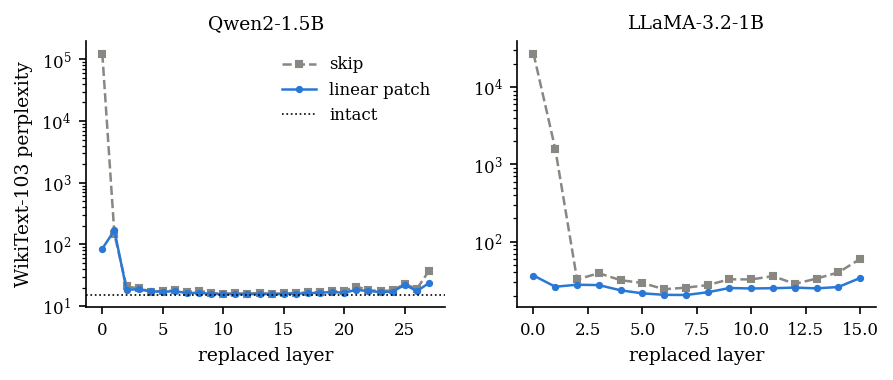

saved fig4_multilayer


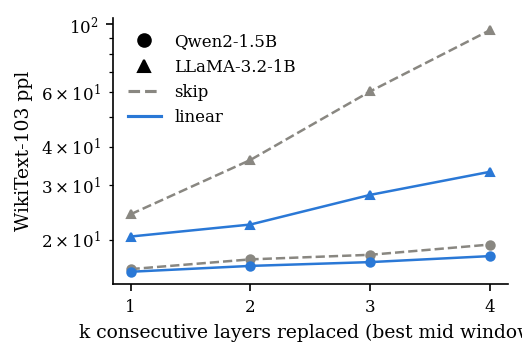

saved fig5_rank


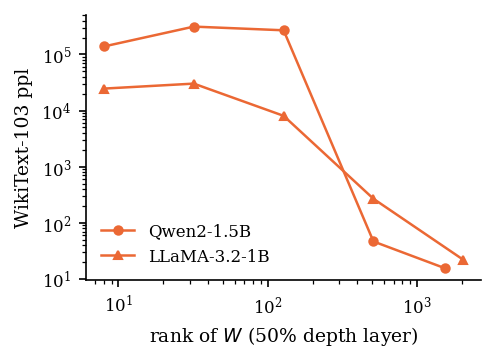

saved fig6_crossdomain


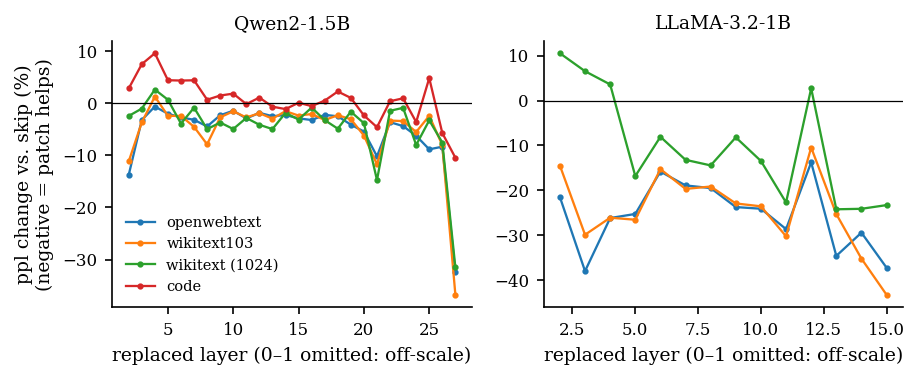

'# ---- Table 1 (LaTeX): tasks ----\nfor key, label in MODELS.items():\n    t = load(key, "tasks.csv")\n    if t is None: continue\n    print(f"\n% ---- {label} tasks table ----")\n    print(t.to_latex(index=False, float_format="%.3f"))\n\nprint("\nAll figures in:", FIG)'

In [ ]:
# =============================================================
# Paper figures — paste as ONE Colab cell (or %run figures.py)
# Reads results from OUT, writes PDF (for LaTeX) + PNG previews
# to {OUT}/../figs/. Rerun anytime; it only reads CSVs.
# =============================================================
import os, ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT = "/content/drive/MyDrive/blackboxnlp/results"
FIG = os.path.join(os.path.dirname(OUT), "figs")
os.makedirs(FIG, exist_ok=True)

MODELS = {"qwen2-1.5b": "Qwen2-1.5B", "llama3.2-1b": "LLaMA-3.2-1B"}
C = {"full": "#2a78d6", "ident": "#898781", "delta": "#eb6834",
     "skip": "#898781", "linear": "#2a78d6", "rand": "#b3b0a9"}

# ACL-friendly styling: serif, small, crisp
plt.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.titlesize": 9,
    "axes.labelsize": 9, "legend.fontsize": 8, "xtick.labelsize": 8,
    "ytick.labelsize": 8, "figure.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
})

def load(key, name):
    p = os.path.join(OUT, key, name)
    return pd.read_csv(p) if os.path.exists(p) else None

def save(fig, name):
    fig.savefig(os.path.join(FIG, f"{name}.pdf"))
    fig.savefig(os.path.join(FIG, f"{name}.png"), dpi=300)
    #print("saved", name)
    plt.show(); plt.close(fig)

def depth(df):  # normalized depth for cross-model comparison
    return df.layer / df.layer.max()

# ---- Fig 1 (CENTRAL): Δ-R² U-shape, trained vs random init ----
fig, ax = plt.subplots(figsize=(3.4, 2.4))
marks = {"qwen2-1.5b": "o", "llama3.2-1b": "^"}
for key, label in MODELS.items():
    r2 = load(key, "r2.csv"); rnd = load(key, "r2_randinit.csv")
    if r2 is None: continue
    r2 = r2[r2["stack"] == "main"] if "stack" in r2 else r2
    ax.errorbar(depth(r2), r2.r2_delta, yerr=r2.get("r2_delta_std"),
                marker=marks[key], ms=3, lw=1.3, label=f"{label} (trained)",
                color=C["delta"] if "llama" in key else C["full"])
    if rnd is not None:
        rnd = rnd[rnd["stack"] == "main"] if "stack" in rnd else rnd
        rnd = rnd[rnd.layer < rnd.layer.max()]  # drop last-layer norm artifact
        ax.plot(depth(rnd), rnd.r2_delta, marks[key], ls="--", ms=2, lw=1,
                color=C["rand"], label=f"{label} (random init)")
ax.set(xlabel="normalized depth", ylabel="update ($\\Delta$) held-out $R^2$",
       ylim=(0, 1.05))
ax.legend(frameon=False, loc="upper center", ncol=2, handlelength=1.6)
save(fig, "fig1_delta_ushape")

# ---- Fig 2: three-curve R² per model (full / identity / Δ) ----
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.3), sharey=True)
for ax, (key, label) in zip(axes, MODELS.items()):
    r2 = load(key, "r2.csv")
    if r2 is None: continue
    r2 = r2[r2["stack"] == "main"] if "stack" in r2 else r2
    ax.plot(r2.layer, r2.r2_full, "o-", ms=2.5, lw=1.2, color=C["full"],
            label="linear (full state)")
    ax.plot(r2.layer, r2.r2_identity, "s--", ms=2.5, lw=1.2, color=C["ident"],
            label="identity (residual)")
    ax.plot(r2.layer, r2.r2_delta, "^-", ms=2.5, lw=1.2, color=C["delta"],
            label="linear ($\\Delta$ target)")
    ax.set(title=label, xlabel="layer", ylim=(-0.5, 1.05))
axes[0].set_ylabel("held-out $R^2$")
axes[0].legend(frameon=False, loc="lower center")
save(fig, "fig2_r2_three_curves")

# ---- Fig 3: substitutability profile (WikiText ppl, log) ----
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.3))
INTACT = {"qwen2-1.5b": 15.172}          # add llama intact ppl when you have it
for ax, (key, label) in zip(axes, MODELS.items()):
    sw = load(key, "sweep_wikitext103.csv")
    if sw is None: continue
    ax.plot(sw.layer, sw.skip, "s--", ms=2.5, lw=1.2, color=C["skip"], label="skip")
    ax.plot(sw.layer, sw.linear, "o-", ms=2.5, lw=1.2, color=C["linear"],
            label="linear patch")
    if key in INTACT:
        ax.axhline(INTACT[key], color="k", lw=0.8, ls=":", label="intact")
    ax.set(title=label, xlabel="replaced layer", yscale="log")
axes[0].set_ylabel("WikiText-103 perplexity")
axes[0].legend(frameon=False)
save(fig, "fig3_substitutability_profile")

# ---- Fig 4: multi-layer (node failure) — best window per k ----
fig, ax = plt.subplots(figsize=(3.4, 2.3))
for key, label in MODELS.items():
    mu = load(key, "multi.csv")
    if mu is None: continue
    mid = mu[(mu.start >= mu.start.max() * .25) & (mu.start <= mu.start.max() * .75)]
    best = mid.groupby("k").agg(skip=("skip", "min"), linear=("linear", "min"))
    m = marks[key]
    ax.plot(best.index, best.skip, m + "--", ms=4, lw=1.2, color=C["skip"])
    ax.plot(best.index, best.linear, m + "-", ms=4, lw=1.2, color=C["linear"])
    ax.plot([], [], m, color="k", label=label)
ax.plot([], [], "--", color=C["skip"], label="skip")
ax.plot([], [], "-", color=C["linear"], label="linear")
ax.set(xlabel="k consecutive layers replaced (best mid window)",
       ylabel="WikiText-103 ppl", yscale="log", xticks=[1, 2, 3, 4])
ax.legend(frameon=False)
save(fig, "fig4_multilayer")

# ---- Fig 5: rank sweep ----
fig, ax = plt.subplots(figsize=(3.4, 2.3))
for key, label in MODELS.items():
    rk = load(key, "rank.csv")
    if rk is None: continue
    mid = rk[rk.layer == sorted(rk.layer.unique())[1]]   # 50%-depth layer
    ax.plot(mid["rank"], mid.metric, marks[key] + "-", ms=4, lw=1.2,
            color=C["delta"], label=label)
ax.set(xlabel="rank of $W$ (50% depth layer)", ylabel="WikiText-103 ppl",
       xscale="log", yscale="log")
ax.legend(frameon=False)
save(fig, "fig5_rank")

# ---- Fig 6: cross-domain patch cost (linear − skip, sign of help) ----
doms = ["openwebtext", "wikitext103", "wikitext103_long", "code"]
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.3), sharey=False)
for ax, (key, label) in zip(axes, MODELS.items()):
    for d in doms:
        sw = load(key, f"sweep_{d}.csv")
        if sw is None: continue
        rel = (sw.linear - sw.skip) / sw.skip * 100   # % change vs skip
        ax.plot(sw.layer[2:], rel[2:], "-", lw=1.1, ms=2, marker="o",
                label=d.replace("wikitext103_long", "wikitext (1024)"))
    ax.axhline(0, color="k", lw=0.6)
    ax.set(title=label, xlabel="replaced layer (0–1 omitted: off-scale)")
axes[0].set_ylabel("ppl change vs. skip (%)\n(negative = patch helps)")
axes[0].legend(frameon=False, fontsize=7)
save(fig, "fig6_crossdomain")

"""# ---- Table 1 (LaTeX): tasks ----
for key, label in MODELS.items():
    t = load(key, "tasks.csv")
    if t is None: continue
    print(f"\n% ---- {label} tasks table ----")
    print(t.to_latex(index=False, float_format="%.3f"))

print("\nAll figures in:", FIG)"""

## Encoders + enc-dec (additional maybe)

In [ ]:
!python run.py --model bert-base --stage fit ppl multi mlp randinit --out $OUT

2026-07-14 18:25:30.170770: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-07-14 18:25:30.217430: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
model.safetensors:  15% 67.1M/440M [00:20<00:18, 20.5MB/s]Cancellation requested; stopping current tasks.
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py", line 633, in xet_get
    download_files(
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/pipeline-3/run.py", line 237, in <module>
    main()
  File "/content/pipeline-3/run.py", line 125, in main
    tok, model = M.load(spe

In [ ]:
!python run.py --model roberta-base --stage fit ppl multi mlp randinit --out $OUT

object address  : 0x7b32358558a0
object refcount : 3
object type     : 0xa284e0
object type name: KeyboardInterrupt
object repr     : KeyboardInterrupt()
lost sys.stderr
^C


In [ ]:
!python run.py --model bart-base --stage fit randinit --out $OUT

config.json: 1.72kB [00:00, 385kB/s]
vocab.json: 899kB [00:00, 14.9MB/s]
merges.txt: 456kB [00:00, 14.2MB/s]
tokenizer.json: 1.36MB [00:00, 9.15MB/s]
2026-07-14 18:26:13.133850: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-07-14 18:26:13.179937: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
model.safetensors:   0% 0.00/558M [00:00<?, ?B/s]Cancellation requested; stopping current tasks.
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py", line 633, in xet_get
    download_files(
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/co

In [ ]:
!python run.py --model t5-base --stage fit randinit --out $OUT

config.json: 1.21kB [00:00, 4.76MB/s]
spiece.model: 100% 792k/792k [00:00<00:00, 22.0MB/s]
tokenizer.json: 1.39MB [00:00, 5.85MB/s]
2026-07-14 18:27:04.931823: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-07-14 18:27:04.973744: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Traceback (most recent call last):
  File "/content/pipeline-3/run.py", line 237, in <module>
  File "/content/pipeline-3/run.py", line 125, in main
    tok, model = M.load(spec, device)
                 ^^^^^^^^^^^^^^^^^^^^
  File "/content/pipeline-3/subst/models.py", line 20, in load
    model = cls.from_pretrained(spec.hf_name, torch_dtype=dtype).to(device).eval()
            ^^^^^^^^^^^^^^^^^^^^^^^^^

In [ ]:
!rm -rf ~/.cache/huggingface/hub/models--bert-base

In [ ]:
!python run.py --model bert-base    --stage fit randinit --out $OUT


tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 427kB/s]
config.json: 100% 570/570 [00:00<00:00, 5.72MB/s]
vocab.txt: 232kB [00:00, 3.75MB/s]
tokenizer.json: 466kB [00:00, 14.8MB/s]
2026-07-14 18:34:50.038813: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
model.safetensors: 100% 440M/440M [00:02<00:00, 162MB/s]
BertForMaskedLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly overwritten. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with

In [ ]:

!python run.py --model t5-base   --stage randinit --out $OUT


python3: can't open file '/content/run.py': [Errno 2] No such file or directory


In [ ]:
!python run.py --model bart-base    --stage fit randinit --out $OUT


In [ ]:
!python run.py --model t5-base      --stage fit randinit --out $OUT

In [ ]:


# 2. mount Drive
from google.colab import drive
drive.mount('/content/drive')
OUT = "/content/drive/MyDrive/blackboxnlp/results"



Mounted at /content/drive


In [ ]:
# 3. install + unzip the pipeline
!pip -q install transformers==4.46.3 datasets==3.1.0 accelerate pandas matplotlib
!unzip -oq pipeline-5.zip -d /content/
%cd /content/pipeline-5

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 84.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 43.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 106.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.19.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.9.0 which is incompatible.
/content/pipeline-5


In [ ]:
!python run.py --model qwen2-1.5b  --stage repair --out $OUT


tokenizer_config.json: 1.29kB [00:00, 5.14MB/s]
vocab.json: 2.78MB [00:00, 50.1MB/s]
merges.txt: 1.67MB [00:00, 136MB/s]
tokenizer.json: 7.03MB [00:00, 180MB/s]
config.json: 100% 662/662 [00:00<00:00, 7.37MB/s]
2026-07-15 18:27:59.337929: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
model.safetensors: 100% 3.09G/3.09G [00:10<00:00, 293MB/s]
generation_config.json: 100% 138/138 [00:00<00:00, 1.65MB/s]
Resolving data files: 100% 80/80 [00:00<00:00, 1195.75it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
README.md: 10.5kB [00:00, 39.8MB/s]
wikitext-103-raw-v1/test-00000-of-00001.(…): 100% 733k/733k [00:00<00:00, 4.85MB/s]
wikitext-103-raw-v1/train-00000-of-00002(…): 100% 157M/157M [00:01<00:00, 91.1MB/s]
wikitext-103-raw

In [ ]:
import os
OUT = "/content/drive/MyDrive/blackboxnlp/results"
for m in ["qwen2-1.5b","llama3.2-1b","bert-base","roberta-base","bart-base","t5-base"]:
    p = f"{OUT}/{m}"
    print(m, ":", sorted(os.listdir(p)) if os.path.isdir(p) else "MISSING")

qwen2-1.5b : ['W.pt', 'mlp.csv', 'multi.csv', 'r2.csv', 'r2_randinit.csv', 'rank.csv', 'sweep_code.csv', 'sweep_openwebtext.csv', 'sweep_wikitext103.csv', 'sweep_wikitext103_long.csv', 'tasks.csv']
llama3.2-1b : ['W.pt', 'mlp.csv', 'multi.csv', 'r2.csv', 'r2_randinit.csv', 'rank.csv', 'sweep_code.csv', 'sweep_openwebtext.csv', 'sweep_wikitext103.csv', 'tasks.csv']
bert-base : ['W.pt', 'W_randinit.pt', 'r2.csv', 'r2_randinit.csv']
roberta-base : ['W.pt', 'W_randinit.pt', 'r2.csv', 'r2_randinit.csv']
bart-base : ['W.pt', 'r2.csv']
t5-base : ['W.pt', 'r2.csv']


saved fig1_delta_ushape_all


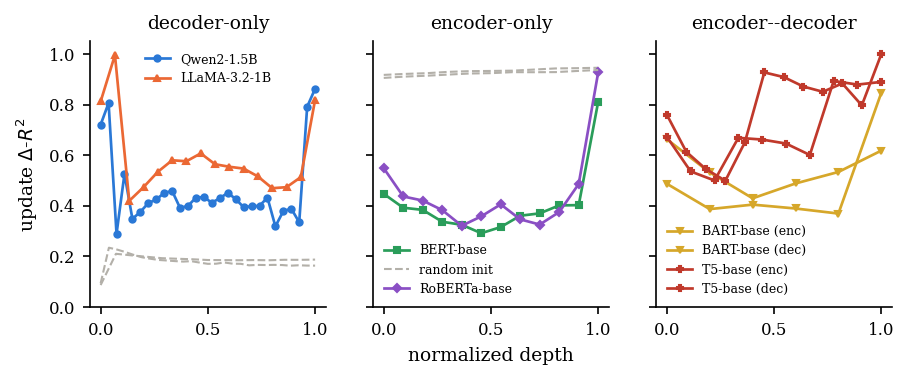

saved fig2_r2_three_curves


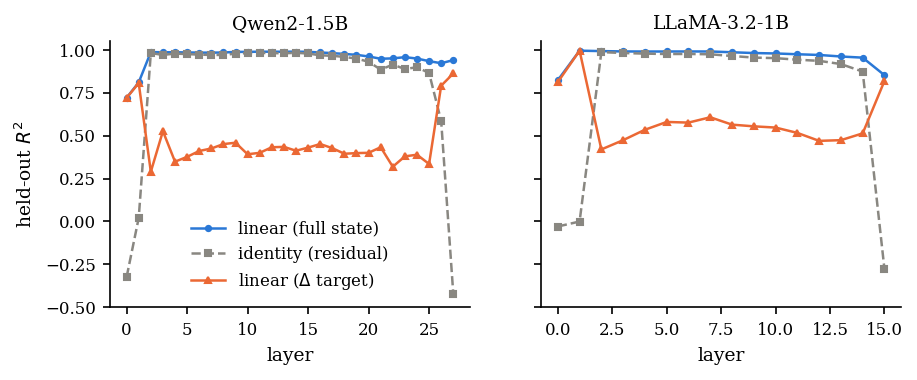

saved fig3_substitutability_profile


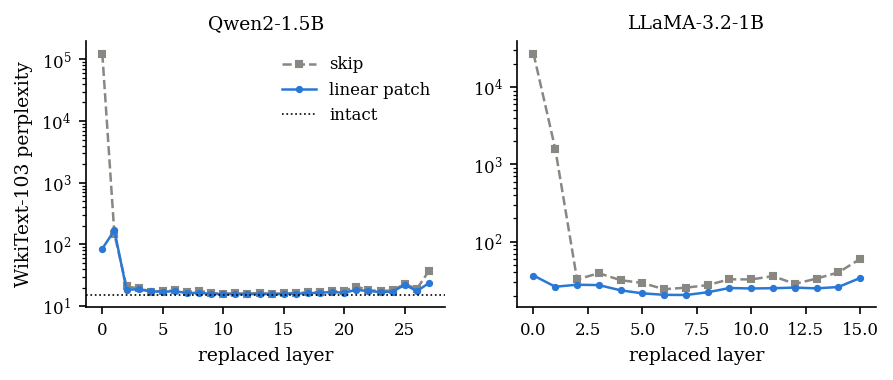

NameError: name 'marks' is not defined

In [ ]:
get_ipython().run_line_magic('run', '/content/figures.py')

In [ ]:
import pandas as pd
# if your sweep CSVs happen to have stored it, else rerun:
!python run.py --model llama3.2-1b --stage ppl --force --out $OUT

tokenizer_config.json: 50.5kB [00:00, 120MB/s]
tokenizer.json: 9.09MB [00:00, 21.6MB/s]
special_tokens_map.json: 100% 301/301 [00:00<00:00, 2.25MB/s]
config.json: 100% 843/843 [00:00<00:00, 6.52MB/s]
2026-07-15 19:14:09.436305: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
model.safetensors: 100% 2.47G/2.47G [00:07<00:00, 345MB/s]
generation_config.json: 100% 185/185 [00:00<00:00, 1.49MB/s]
Resolving data files: 100% 80/80 [00:00<00:00, 406.19it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
llama3.2-1b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[load_fit] valcache.pt missing; will rebuild if a stag

In [ ]:
!python run.py --model bert-base    --stage ppl multi --out $OUT


tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 351kB/s]
config.json: 100% 570/570 [00:00<00:00, 4.32MB/s]
vocab.txt: 232kB [00:00, 9.98MB/s]
tokenizer.json: 466kB [00:00, 36.0MB/s]
2026-07-15 19:20:07.903836: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
model.safetensors: 100% 440M/440M [00:01<00:00, 362MB/s]
BertForMaskedLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly overwritten. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with

In [ ]:
!python run.py --model roberta-base --stage ppl multi --out $OUT

tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 142kB/s]
config.json: 100% 481/481 [00:00<00:00, 4.27MB/s]
vocab.json: 899kB [00:00, 6.94MB/s]
merges.txt: 456kB [00:00, 1.99MB/s]
tokenizer.json: 1.36MB [00:00, 21.9MB/s]
2026-07-15 19:54:29.318530: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
model.safetensors: 100% 499M/499M [00:02<00:00, 232MB/s]
Resolving data files: 100% 80/80 [00:00<00:00, 191.78it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
README.md: 10.5kB [00:00, 18.1MB/s]
wikitext-103-raw-v1/test-00000-of-00001.(…): 100% 733k/733k [00:00<00:00, 2.06MB/s]
wikitext-103-raw-v1/train-00000-of-00002(…): 100% 157M/157M [00:01<00:00, 104MB/s]
wikitext-103-raw-v1/train-00001-of-00002(…): 100% 157M/157M [00:01<0

In [ ]:
import pandas as pd
for m in ["bert-base","roberta-base"]:
    for f in ["sweep_wikitext103.csv","multi.csv"]:
        try:
            print(f"\n=== {m}/{f} ===")
            print(pd.read_csv(f"{OUT}/{m}/{f}").to_string(index=False))
        except Exception as e: print(m, f, e)


=== bert-base/sweep_wikitext103.csv ===
 layer                                    skip                                  linear
     0 {'mlm_acc': 0.5228, 'mlm_loss': 2.7499} {'mlm_acc': 0.5424, 'mlm_loss': 2.5829}
     1 {'mlm_acc': 0.5525, 'mlm_loss': 2.4866} {'mlm_acc': 0.5553, 'mlm_loss': 2.5166}
     2 {'mlm_acc': 0.5434, 'mlm_loss': 2.5819} {'mlm_acc': 0.5442, 'mlm_loss': 2.5418}
     3  {'mlm_acc': 0.555, 'mlm_loss': 2.4639} {'mlm_acc': 0.5473, 'mlm_loss': 2.4773}
     4 {'mlm_acc': 0.5544, 'mlm_loss': 2.4132} {'mlm_acc': 0.5533, 'mlm_loss': 2.4151}
     5 {'mlm_acc': 0.5618, 'mlm_loss': 2.3881} {'mlm_acc': 0.5618, 'mlm_loss': 2.3701}
     6 {'mlm_acc': 0.5609, 'mlm_loss': 2.4183} {'mlm_acc': 0.5574, 'mlm_loss': 2.4049}
     7  {'mlm_acc': 0.556, 'mlm_loss': 2.4497} {'mlm_acc': 0.5492, 'mlm_loss': 2.4722}
     8 {'mlm_acc': 0.5521, 'mlm_loss': 2.4622} {'mlm_acc': 0.5489, 'mlm_loss': 2.4835}
     9  {'mlm_acc': 0.541, 'mlm_loss': 2.4902} {'mlm_acc': 0.5382, 'mlm_loss': 2.5492}
  

In [7]:
!cp /content/run-3.py /content/pipeline-5/run.py
!cp /content/evals.py /content/pipeline-5/subst/evals.py
!python run.py --model qwen2-1.5b --stage repair --out $OUT

tokenizer_config.json: 1.29kB [00:00, 2.37MB/s]
vocab.json: 2.78MB [00:00, 52.3MB/s]
merges.txt: 1.67MB [00:00, 89.0MB/s]
tokenizer.json: 7.03MB [00:00, 195MB/s]
config.json: 100% 662/662 [00:00<00:00, 6.79MB/s]
2026-07-16 16:30:42.827288: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
model.safetensors: 100% 3.09G/3.09G [00:09<00:00, 310MB/s]
generation_config.json: 100% 138/138 [00:00<00:00, 1.23MB/s]
Resolving data files: 100% 80/80 [00:00<00:00, 331.89it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
README.md: 10.5kB [00:00, 24.0MB/s]
wikitext-103-raw-v1/test-00000-of-00001.(…): 100% 733k/733k [00:00<00:00, 4.29MB/s]
wikitext-103-raw-v1/train-00000-of-00002(…): 100% 157M/157M [00:01<00:00, 101MB/s]
wikitext-103-raw-

In [8]:
!cp /content/run-4.py /content/pipeline-5/run.py
!cp /content/evals-2.py /content/pipeline-5/subst/evals.py
!python run.py --model qwen2-1.5b --stage repair --out $OUT

2026-07-16 16:57:23.938872: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 445.29it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[repair] statistics pass: 100% 188/188 [04:02<00:00,  1.29s/it]
Traceback (most recent call last):
  File "/content/pipeline-5/run.py", line 316, in <module>
    main()
  File "/content/pipeline-5/run.py", line 271, in main
    repair_hard_layers(model, layers, Wmain, acc, caches, stack, ef, L,
  File "/content/pipeline-5/subst/evals.py", line 179, in repair_hard_layers
  

In [ ]:
!cp /content/evals-3.py /content/pipeline-5/subst/evals.py
!python run.py --model qwen2-1.5b --stage repair --out $OUT

2026-07-16 17:08:36.713530: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Resolving data files: 100% 80/80 [00:00<00:00, 271.48it/s]
[data] fit/eval web corpus: OpenWebText (parquet branch) (6500 docs)
Repo card metadata block was not found. Setting CardData to empty.
qwen2-1.5b: 6000 fit / 200 val docs; eval domains: ['openwebtext', 'wikitext103', 'wikitext103_long', 'code']
[repair] statistics pass: 100% 188/188 [04:01<00:00,  1.29s/it]
  L0 lowrank_r64: 385.969
  L0 lowrank_r256: 81.414
  L0 lowrank_r512: 65.498
  L0 neighbor_L1: 3436102.906
  L1 skip: 126.742
  L1 linear_full: 158.656
  L1 lowrank_r64: 972.76
  L1 lowrank_r256: 284.878
  L1 lowrank_r512: 209.444
  L1 neighbor_L0: 666917.868
  L26 skip: 17.224
  L26 linear_full: 15.841
  L26

## Optional: Pythia scale ladder (cut first if behind schedule)

In [ ]:
for m in ["pythia-160m","pythia-410m","pythia-1.4b"]:
    !python run.py --model {m} --stage fit --out $OUT